# Problem Ordering for Gridsearch Data

This notebook:
1. loads all gridsearch CSVs in one pass,
2. ranks the 24 Tower of London problems by the mean number of moves taken on success,
3. puts unfinished problems last with `NaN` as their mean value,
4. compares each ranked list against `problems_ordered_Healthy.csv` with Kendall tau,
5. displays the rank-correlation values in an `alpha`/`beta` grid.

In [ ]:
from pathlib import Path
import ast

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.stats import kendalltau

# Resolve project root robustly from the notebook location.
project_root = Path.cwd()
for candidate in [project_root, *project_root.parents]:
    if (candidate / "tower_of_london_plots").exists() and (candidate / "src").exists():
        project_root = candidate
        break
else:
    project_root = Path(r"c:/Users/Michael Migacev/Desktop/UNI/Wirklich_UNI/AICON/master-thesis-tol/master-thesis-tol")

grid_dir = project_root / "tower_of_london_plots" / "gridsearch_bf_md_scf_attresh0-1_0p05"
healthy_order_path = project_root / "src" / "tower_of_london_human_data" / "problems_ordered_Healthy.csv"

csv_files = sorted(grid_dir.glob("gridsearch_bf_md_scf_atresh*.csv"))
if not csv_files:
    raise FileNotFoundError(f"No matching gridsearch CSVs found in: {grid_dir}")

if not healthy_order_path.exists():
    raise FileNotFoundError(f"MCI ordering CSV not found: {healthy_order_path}")


def normalize_tol_id(value: str) -> str:
    num = int(str(value).split("-")[-1])
    return f"TOL-ID-{num:02d}"


healthy_df = pd.read_csv(healthy_order_path)
if "TOL-ID" not in healthy_df.columns:
    raise ValueError("Expected column 'TOL-ID' in problems_ordered_Healthy.csv")

healthy_df = healthy_df.copy()
healthy_df["TOL-ID"] = healthy_df["TOL-ID"].map(normalize_tol_id)
healthy_df["healthy_rank"] = np.arange(1, len(healthy_df) + 1)
healthy_rank_map = dict(zip(healthy_df["TOL-ID"], healthy_df["healthy_rank"]))

ref_df = pd.read_csv(csv_files[0])
required_cols = {"init", "goal", "num_moves", "finished", "moves taken", "alpha", "beta"}
missing_cols = required_cols - set(ref_df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns in gridsearch data: {missing_cols}")

problem_map = (
    ref_df[["init", "goal"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)
problem_map["TOL-ID"] = [f"TOL-ID-{index:02d}" for index in range(1, len(problem_map) + 1)]
problem_map["healthy_rank"] = problem_map["TOL-ID"].map(healthy_rank_map)

if problem_map["healthy_rank"].isna().any():
    missing_ids = problem_map.loc[problem_map["healthy_rank"].isna(), "TOL-ID"].tolist()
    raise ValueError(f"Missing healthy rank entries for TOL IDs: {missing_ids}")

print(f"Project root: {project_root}")
print(f"Gridsearch CSV files found: {len(csv_files)}")
print(f"Healthy ordering entries: {len(healthy_df)}")
print(f"Unique problems in gridsearch data: {len(problem_map)}")

Project root: c:\Users\Michael Migacev\Desktop\UNI\Wirklich_UNI\AICON\master-thesis-tol\master-thesis-tol
Gridsearch CSV files found: 400
Healthy ordering entries: 24
Unique problems in gridsearch data: 24


In [36]:
# Build a canonical problem map (init->goal -> TOL-ID) from first file order.
ref_df = pd.read_csv(csv_files[0])
required_cols = {"init", "goal", "num_moves", "finished", "alpha", "beta"}
missing_cols = required_cols - set(ref_df.columns)
if missing_cols:
    raise ValueError(f"Missing required columns in gridsearch data: {missing_cols}")

problem_map = (
    ref_df[["init", "goal"]]
    .drop_duplicates()
    .reset_index(drop=True)
    .copy()
)
problem_map["tol_num"] = np.arange(1, len(problem_map) + 1)
problem_map["TOL-ID"] = problem_map["tol_num"].map(lambda x: f"TOL-ID-{x:02d}")

if len(problem_map) != 24:
    print(f"Warning: Expected 24 unique problems, got {len(problem_map)}")

def optimal_moves_for_tol_num(tol_num: int) -> int:
    if 1 <= tol_num <= 8:
        return 4
    if 9 <= tol_num <= 16:
        return 5
    if 17 <= tol_num <= 24:
        return 6
    raise ValueError(f"Unexpected TOL problem number: {tol_num}")

problem_map["optimal_moves"] = problem_map["tol_num"].map(optimal_moves_for_tol_num)

problem_map.head(24)

,init,goal,tol_num,TOL-ID,optimal_moves
0,54,31,1,TOL-ID-01,4
1,42,23,2,TOL-ID-02,4
2,34,13,3,TOL-ID-03,4
3,12,65,4,TOL-ID-04,4
4,55,41,5,TOL-ID-05,4
5,16,24,6,TOL-ID-06,4
6,25,32,7,TOL-ID-07,4
7,36,15,8,TOL-ID-08,4
8,33,11,9,TOL-ID-09,5
9,53,13,10,TOL-ID-10,5


In [37]:
def format_param(value: float) -> str:
    return str(value).replace("-", "m").replace(".", "p")


def to_bool_series(series: pd.Series) -> pd.Series:
    return series.map(lambda value: str(value).strip().lower() == "true")


def parse_moves_taken(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (list, tuple)):
        return len(value)
    return len(ast.literal_eval(value))


def rank_problems_for_file(file_path: Path) -> pd.DataFrame:
    df = pd.read_csv(file_path)

    missing = required_cols - set(df.columns)
    if missing:
        raise ValueError(f"{file_path.name} missing required columns: {missing}")

    df = df.merge(problem_map, on=["init", "goal"], how="left")
    if df["TOL-ID"].isna().any():
        missing_pairs = df.loc[df["TOL-ID"].isna(), ["init", "goal"]].drop_duplicates()
        raise ValueError(f"Unknown problems in {file_path.name}:\n{missing_pairs}")

    if "optimal_moves" not in df.columns:
        raise ValueError("Expected 'optimal_moves' to be present from the TOL-ID mapping cell.")

    df["finished"] = to_bool_series(df["finished"])
    df["moves_taken_count"] = df["moves taken"].map(parse_moves_taken)
    df["extra_moves_on_success"] = np.where(
        df["finished"],
        df["moves_taken_count"] - df["optimal_moves"],
        np.nan,
    )

    agg = (
        df.groupby(["alpha", "beta", "TOL-ID"], as_index=False)
        .agg(
            mean_extra_moves_on_success=("extra_moves_on_success", "mean"),
            success_count=("finished", "sum"),
            total_runs=("finished", "size"),
        )
    )

    agg["healthy_rank"] = agg["TOL-ID"].map(healthy_rank_map).astype(int)
    agg["_sort_mean"] = agg["mean_extra_moves_on_success"].fillna(np.inf)
    agg = agg.sort_values(["_sort_mean", "healthy_rank", "TOL-ID"], ascending=[True, True, True]).reset_index(drop=True)
    agg["ordered_position"] = np.arange(1, len(agg) + 1)

    result = agg.drop(columns=["_sort_mean"])
    return result[[
        "alpha",
        "beta",
        "ordered_position",
        "TOL-ID",
        "mean_extra_moves_on_success",
        "success_count",
        "total_runs",
        "healthy_rank",
    ]]

In [38]:
analysis_rows = []
ordered_tables = {}

for file_path in csv_files:
    ordered_df = rank_problems_for_file(file_path)
    alpha = float(ordered_df["alpha"].iloc[0])
    beta = float(ordered_df["beta"].iloc[0])

    ordered_tables[(alpha, beta)] = ordered_df
    analysis_rows.append(
        {
            "alpha": alpha,
            "beta": beta,
            "num_compared": int(len(ordered_df)),
            "num_solved": int(ordered_df["mean_extra_moves_on_success"].notna().sum()),
            "solved_ratio": float(ordered_df["mean_extra_moves_on_success"].notna().mean()),
            "mean_of_mean_extra_moves_on_success": float(ordered_df["mean_extra_moves_on_success"].mean()),
        }
    )

summary_df = pd.DataFrame(analysis_rows).sort_values(["alpha", "beta"]).reset_index(drop=True)
display(summary_df)

,alpha,beta,num_compared,num_solved,solved_ratio,mean_of_mean_extra_moves_on_success
0,0.0,0.00,24,0,0.000000,NaN
1,0.0,0.05,24,0,0.000000,NaN
2,0.0,0.15,24,0,0.000000,NaN
3,0.0,0.20,24,0,0.000000,NaN
4,0.0,0.25,24,0,0.000000,NaN
...,...,...,...,...,...,...
395,1.0,0.80,24,17,0.708333,2.941176
396,1.0,0.85,24,17,0.708333,2.941176
397,1.0,0.90,24,16,0.666667,2.562500
398,1.0,0.95,24,16,0.666667,2.562500


In [39]:
from pathlib import Path

import numpy as np
import pandas as pd
from scipy.stats import kendalltau

# Compare BFS bidirectional ordering with healthy ordering via Kendall tau.
if "project_root" not in globals():
    project_root = Path.cwd()
    for candidate in [project_root, *project_root.parents]:
        if (candidate / "tower_of_london_plots").exists() and (candidate / "src").exists():
            project_root = candidate
            break

if "normalize_tol_id" not in globals():
    def normalize_tol_id(value: str) -> str:
        num = int(str(value).split("-")[-1])
        return f"TOL-ID-{num:02d}"

if "healthy_rank_map" not in globals():
    healthy_order_path = project_root / "src" / "tower_of_london_human_data" / "problems_ordered_Healthy.csv"
    healthy_df = pd.read_csv(healthy_order_path)
    healthy_df["TOL-ID"] = healthy_df["TOL-ID"].map(normalize_tol_id)
    healthy_df["healthy_rank"] = np.arange(1, len(healthy_df) + 1)
    healthy_rank_map = dict(zip(healthy_df["TOL-ID"], healthy_df["healthy_rank"]))

bfs_path = project_root / "src" / "tower_of_london_human_data" / "bfs_bidirectional_avg_nodes.csv"
bfs_df = pd.read_csv(bfs_path)

required_bfs_cols = {"problem_id", "avg_nodes_examined"}
missing_bfs_cols = required_bfs_cols - set(bfs_df.columns)
if missing_bfs_cols:
    raise ValueError(f"BFS CSV missing required columns: {missing_bfs_cols}")

# Convert TOL-P-01 style IDs to TOL-ID-01 so they can be compared directly.
bfs_df = bfs_df.copy()
bfs_df["TOL-ID"] = bfs_df["problem_id"].map(lambda value: normalize_tol_id(str(value).replace("TOL-P", "TOL-ID")))
bfs_df["healthy_rank"] = bfs_df["TOL-ID"].map(healthy_rank_map)

if bfs_df["healthy_rank"].isna().any():
    missing_ids = bfs_df.loc[bfs_df["healthy_rank"].isna(), "problem_id"].tolist()
    raise ValueError(f"Missing healthy rank for BFS problem IDs: {missing_ids}")

bfs_ranked = bfs_df.sort_values(["avg_nodes_examined", "healthy_rank", "TOL-ID"], ascending=[True, True, True]).reset_index(drop=True)
bfs_ranked["bfs_rank"] = np.arange(1, len(bfs_ranked) + 1)

tau_value, p_value = kendalltau(bfs_ranked["bfs_rank"], bfs_ranked["healthy_rank"])

print(f"BFS vs Healthy EM Kendall tau: {tau_value:.4f} (p-value={p_value:.4e})")
#display(bfs_ranked[["bfs_rank", "TOL-ID", "avg_nodes_examined", "healthy_rank"]])

BFS vs Healthy EM Kendall tau: 0.7464 (p-value=9.9543e-09)


In [40]:
print(f"BFS vs Healthy EM Kendall tau: {tau_value:.4f} (p-value={p_value:.4e})")

BFS vs Healthy EM Kendall tau: 0.7464 (p-value=9.9543e-09)


In [41]:
# Monte Carlo Kendall tau with random tie resolution (1000 runs per alpha/beta).
num_random_tie_runs = 1000
rng_seed = 42
rng = np.random.default_rng(rng_seed)


def random_tie_resolved_order(df: pd.DataFrame, value_col: str, rng: np.random.Generator) -> np.ndarray:
    """Return ordered positions (1..n) after random tie-breaking on value_col.

    Lower value_col ranks earlier. NaN is treated as +inf, and NaN ties are also
    randomly shuffled.
    """
    work = df[["TOL-ID", value_col]].copy()
    work["_sort_value"] = work[value_col].fillna(np.inf)

    ordered_ids = []
    for _, tie_group in work.groupby("_sort_value", sort=True, dropna=False):
        ids = tie_group["TOL-ID"].to_numpy(copy=True)
        rng.shuffle(ids)
        ordered_ids.extend(ids.tolist())

    random_rank_map = {tol_id: rank for rank, tol_id in enumerate(ordered_ids, start=1)}
    return df["TOL-ID"].map(random_rank_map).to_numpy()


random_tie_tau_rows = []

for (alpha, beta), ordered_df in ordered_tables.items():
    tau_values = []

    for _ in range(num_random_tie_runs):
        random_ordered_position = random_tie_resolved_order(
            ordered_df,
            value_col="mean_extra_moves_on_success",
            rng=rng,
        )
        tau, _ = kendalltau(random_ordered_position, ordered_df["healthy_rank"].to_numpy())
        tau_values.append(float(tau))

    random_tie_tau_rows.append(
        {
            "alpha": alpha,
            "beta": beta,
            "kendall_tau_random_tie_mean": float(np.mean(tau_values)),
            "kendall_tau_random_tie_std": float(np.std(tau_values)),
            "num_random_tie_runs": num_random_tie_runs,
        }
    )

random_tie_tau_df = (
    pd.DataFrame(random_tie_tau_rows)
    .sort_values(["alpha", "beta"])
    .reset_index(drop=True)
)

print(
    f"Computed Monte Carlo random-tie Kendall tau for {len(random_tie_tau_df)} "
    f"parameter pairs using {num_random_tie_runs} runs each (seed={rng_seed})."
)
display(random_tie_tau_df.head(20))

Computed Monte Carlo random-tie Kendall tau for 400 parameter pairs using 1000 runs each (seed=42).


,alpha,beta,kendall_tau_random_tie_mean,kendall_tau_random_tie_std,num_random_tie_runs
0,0.0,0.00,-0.000935,0.143977,1000
1,0.0,0.05,-0.004717,0.142074,1000
2,0.0,0.15,0.001174,0.147395,1000
3,0.0,0.20,-0.000384,0.146929,1000
4,0.0,0.25,0.003449,0.143223,1000
5,0.0,0.30,0.003087,0.142299,1000
6,0.0,0.35,0.005420,0.152730,1000
7,0.0,0.40,0.003739,0.140817,1000
8,0.0,0.45,0.001812,0.145265,1000
9,0.0,0.50,0.002333,0.143040,1000


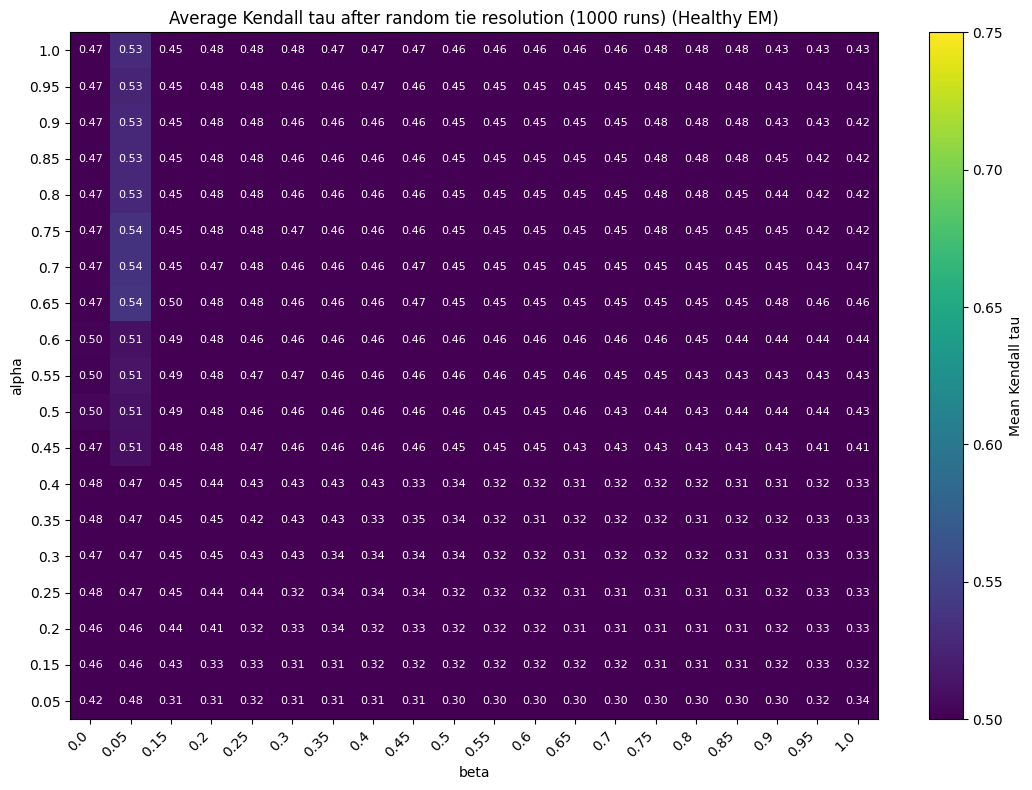

,alpha,beta,kendall_tau_random_tie_mean,kendall_tau_random_tie_std,num_random_tie_runs
241,0.65,0.05,0.538870,0.055281,1000
281,0.75,0.05,0.537022,0.055605,1000
261,0.70,0.05,0.536783,0.054173,1000
381,1.00,0.05,0.531000,0.054914,1000
321,0.85,0.05,0.528732,0.054898,1000
301,0.80,0.05,0.528384,0.053906,1000
341,0.90,0.05,0.528225,0.054791,1000
361,0.95,0.05,0.526181,0.054899,1000
201,0.55,0.05,0.512877,0.041042,1000
181,0.50,0.05,0.511217,0.040738,1000


In [42]:
# Heatmap: average Kendall tau after random tie resolution.
random_tie_tau_grid = (
    random_tie_tau_df
    .pivot(index="alpha", columns="beta", values="kendall_tau_random_tie_mean")
    .sort_index()
    .sort_index(axis=1)
)
plot_random_tie_tau_grid = random_tie_tau_grid[random_tie_tau_grid.index != 0.0]

fig, ax = plt.subplots(figsize=(11, 8))
image = ax.imshow(plot_random_tie_tau_grid.values, aspect="auto", origin="lower", cmap="viridis", vmin=0.5, vmax=0.75)

ax.set_xticks(np.arange(len(plot_random_tie_tau_grid.columns)))
ax.set_yticks(np.arange(len(plot_random_tie_tau_grid.index)))
ax.set_xticklabels([str(value) for value in plot_random_tie_tau_grid.columns], rotation=45, ha="right")
ax.set_yticklabels([str(value) for value in plot_random_tie_tau_grid.index])

ax.set_xlabel("beta")
ax.set_ylabel("alpha")
ax.set_title("Average Kendall tau after random tie resolution (1000 runs) (Healthy EM)")

for row_index in range(plot_random_tie_tau_grid.shape[0]):
    for col_index in range(plot_random_tie_tau_grid.shape[1]):
        value = plot_random_tie_tau_grid.iloc[row_index, col_index]
        label = "nan" if pd.isna(value) else f"{value:.2f}"
        ax.text(col_index, row_index, label, ha="center", va="center", color="white", fontsize=8)

colorbar = fig.colorbar(image, ax=ax)
colorbar.set_label("Mean Kendall tau")

plt.tight_layout()
plt.show()

random_tie_tau_df.sort_values(
    ["kendall_tau_random_tie_mean", "alpha", "beta"],
    ascending=[False, True, True],
).head(20)